# 03 – Exploratory Analysis with SQL

**Objective:** check data quality, measure how well rankings predict results, and find which factors are worth turning into model features.

**Key results**
- **Baseline:** after cleaning, the better-ranked player wins 65.5% of 77,013 matches.
- **Match length matters:** the favourite wins 71.6% of best-of-5 matches, against 63.8% of best-of-3.
- **Ranking gap matters:** the favourite's win rate rises from 55.0% with a small gap to 74.9% with a very large one.
- **Surface matters at player level:** overall rates barely change by surface, but individual players differ a lot.

## 1. Setup

In [1]:
import sqlite3
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

DB_PATH = Path("../data/processed/tennis.db")
conn = sqlite3.connect(DB_PATH)

CHART_COLOR = "#2a78d6"
TEXT_COLOR = "#52514e"
GRID_COLOR = "#e4e3df"


def q(sql):
    """Run a SQL query and return the result as a DataFrame."""
    return pd.read_sql_query(sql, conn)


def style_axes(ax, title):
    """Apply the same clean style to every chart."""
    ax.set_title(title, loc="left", fontsize=12, color="#0b0b0b")
    ax.spines[["top", "right", "left"]].set_visible(False)
    ax.spines["bottom"].set_color(GRID_COLOR)
    ax.grid(axis="y", color=GRID_COLOR, linewidth=0.8)
    ax.set_axisbelow(True)
    ax.tick_params(colors=TEXT_COLOR, length=0)

## 2. Data quality

### How did each match end?

`CASE WHEN` creates a new category from a condition, like an if/else statement. `LIKE` searches inside text, and `%` means "any characters".

In [2]:
q("""
SELECT
    CASE
        WHEN score LIKE '%W/O%' OR score LIKE '%Walkover%' THEN 'Walkover (not played)'
        WHEN score LIKE '%RET%' THEN 'Retirement'
        WHEN score LIKE '%DEF%' THEN 'Default'
        WHEN score LIKE '%ABD%' OR score LIKE '%abandoned%' OR score LIKE '%unfinished%' THEN 'Abandoned'
        ELSE 'Completed'
    END AS outcome,
    COUNT(*) AS n_matches,
    ROUND(100.0 * COUNT(*) / (SELECT COUNT(*) FROM matches), 2) AS pct_of_matches
FROM matches
GROUP BY outcome
ORDER BY n_matches DESC
""")

,outcome,n_matches,pct_of_matches
0,Completed,76481,96.45
1,Retirement,2364,2.98
2,Walkover (not played),423,0.53
3,Default,20,0.03
4,Abandoned,11,0.01


### Are the match durations plausible?

In [3]:
q("""
SELECT t.tourney_name, t.tourney_date, m.round, m.score, m.minutes
FROM matches AS m
JOIN tournaments AS t ON m.tourney_id = t.tourney_id
WHERE m.minutes IS NOT NULL
ORDER BY m.minutes DESC
LIMIT 5
""")

,tourney_name,tourney_date,round,score,minutes
0,Sydney,2016-01-11,QF,7-6(5) 6-3,1146.0
1,Munich,2017-05-01,QF,6-4 3-6 6-2,987.0
2,Wimbledon,2010-06-21,R128,6-4 3-6 6-7(7) 7-6(3) 70-68,665.0
3,Wimbledon,2018-07-02,SF,7-6(6) 6-7(5) 6-7(9) 6-4 26-24,396.0
4,Roland Garros,2004-05-24,R128,6-4 6-3 6-7(5) 3-6 16-14,393.0


**Finding:** the top two durations are impossible. A two-set match in Sydney can't last 1,146 minutes (19 hours), so these are recording errors. The next three are believable: the 665-minute match matches its 70-68 final set. Duration needs a sanity check before it is used in any feature.

### How much data is missing?

`SUM(column IS NULL)` works like the True/False trick in pandas: each missing value counts as 1.

In [4]:
q("""
SELECT
    COUNT(*) AS n_matches,
    ROUND(100.0 * SUM(minutes IS NULL) / COUNT(*), 1) AS pct_no_minutes,
    ROUND(100.0 * SUM(w_svpt IS NULL) / COUNT(*), 1) AS pct_no_serve_stats,
    ROUND(100.0 * SUM(winner_rank IS NULL OR loser_rank IS NULL) / COUNT(*), 1) AS pct_no_ranking
FROM matches
""")

,n_matches,pct_no_minutes,pct_no_serve_stats,pct_no_ranking
0,79299,11.0,8.9,2.4


## 3. Creating a clean view

A **view** is a saved query that behaves like a table. It stores no extra data, and every analysis below can reuse it.

`ranked_matches` keeps the matches that are useful for testing rankings. It removes walkovers, because no tennis was played, and rows where a ranking is missing or the two rankings are equal, because there is no favourite. It also adds the tournament's details and a `favourite_won` column.

In [5]:
conn.executescript("""
DROP VIEW IF EXISTS ranked_matches;

CREATE VIEW ranked_matches AS
SELECT
    m.*,
    t.tourney_name,
    t.surface,
    t.tourney_level,
    t.tourney_date,
    m.winner_rank < m.loser_rank AS favourite_won,
    ABS(m.winner_rank - m.loser_rank) AS rank_gap
FROM matches AS m
JOIN tournaments AS t ON m.tourney_id = t.tourney_id
WHERE m.winner_rank IS NOT NULL
  AND m.loser_rank IS NOT NULL
  AND m.winner_rank <> m.loser_rank
  AND m.score NOT LIKE '%W/O%'
  AND m.score NOT LIKE '%Walkover%';
""")

q("""
SELECT
    COUNT(*) AS n_matches,
    ROUND(100.0 * AVG(favourite_won), 1) AS favourite_win_pct
FROM ranked_matches
""")

,n_matches,favourite_win_pct
0,77013,65.5


## 4. When are rankings most reliable?

### By surface

In [6]:
q("""
SELECT
    surface,
    COUNT(*) AS n_matches,
    ROUND(100.0 * AVG(favourite_won), 1) AS favourite_win_pct
FROM ranked_matches
WHERE surface IS NOT NULL
GROUP BY surface
ORDER BY favourite_win_pct DESC
""")

,surface,n_matches,favourite_win_pct
0,Hard,42145,66.0
1,Grass,7875,65.2
2,Clay,25023,64.8
3,Carpet,1934,63.8


### By match length

Grand Slam men's matches are best of 5 sets, and most other matches are best of 3.

In [7]:
q("""
SELECT
    best_of,
    COUNT(*) AS n_matches,
    ROUND(100.0 * AVG(favourite_won), 1) AS favourite_win_pct,
    ROUND(AVG(minutes), 0) AS avg_minutes
FROM ranked_matches
GROUP BY best_of
""")

,best_of,n_matches,favourite_win_pct,avg_minutes
0,3,60232,63.8,98.0
1,5,16781,71.6,150.0


### By tournament level

`G` = Grand Slam, `M` = Masters 1000, `A` = ATP 250/500, `F` = ATP Finals, `D` = Davis Cup, `O` = Olympics.

In [8]:
q("""
SELECT
    tourney_level,
    COUNT(*) AS n_matches,
    ROUND(100.0 * AVG(favourite_won), 1) AS favourite_win_pct,
    ROUND(AVG(rank_gap), 0) AS avg_rank_gap
FROM ranked_matches
GROUP BY tourney_level
ORDER BY favourite_win_pct DESC
""")

,tourney_level,n_matches,favourite_win_pct,avg_rank_gap
0,O,60,73.3,83.0
1,D,5721,71.8,269.0
2,G,13254,71.2,71.0
3,F,465,64.7,16.0
4,M,15088,64.2,48.0
5,A,42425,63.3,80.0


### By the gap between the two rankings

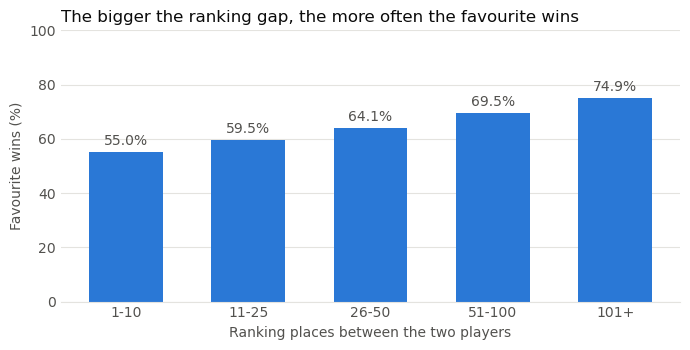

,rank_gap_group,n_matches,favourite_win_pct
0,1-10,10660,55.0
1,11-25,14258,59.5
2,26-50,18295,64.1
3,51-100,17706,69.5
4,101+,16094,74.9


In [9]:
by_gap = q("""
SELECT
    CASE
        WHEN rank_gap <= 10 THEN '1-10'
        WHEN rank_gap <= 25 THEN '11-25'
        WHEN rank_gap <= 50 THEN '26-50'
        WHEN rank_gap <= 100 THEN '51-100'
        ELSE '101+'
    END AS rank_gap_group,
    MIN(rank_gap) AS group_order,
    COUNT(*) AS n_matches,
    ROUND(100.0 * AVG(favourite_won), 1) AS favourite_win_pct
FROM ranked_matches
GROUP BY rank_gap_group
ORDER BY group_order
""")

fig, ax = plt.subplots(figsize=(7, 3.6))
bars = ax.bar(by_gap["rank_gap_group"], by_gap["favourite_win_pct"], color=CHART_COLOR, width=0.6)
ax.bar_label(bars, fmt="%.1f%%", padding=3, color=TEXT_COLOR)
ax.set_ylim(0, 100)
ax.set_xlabel("Ranking places between the two players", color=TEXT_COLOR)
ax.set_ylabel("Favourite wins (%)", color=TEXT_COLOR)
style_axes(ax, "The bigger the ranking gap, the more often the favourite wins")
plt.tight_layout()
plt.show()

by_gap.drop(columns="group_order")

### Over time

2026 is left out because the data stops in June.

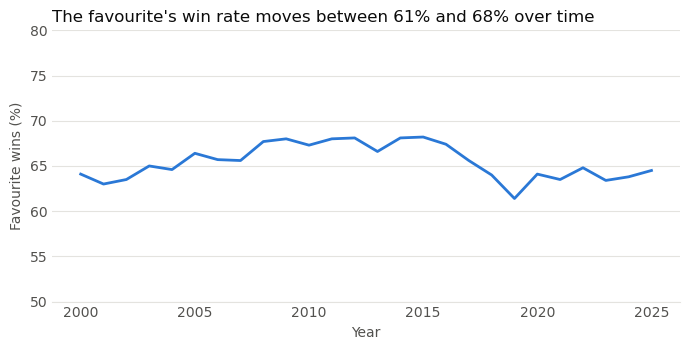

Lowest: 61.4%, highest: 68.2%


In [10]:
by_year = q("""
SELECT
    CAST(substr(tourney_date, 1, 4) AS INTEGER) AS year,
    COUNT(*) AS n_matches,
    ROUND(100.0 * AVG(favourite_won), 1) AS favourite_win_pct
FROM ranked_matches
WHERE tourney_date < '2026-01-01'
GROUP BY year
ORDER BY year
""")

fig, ax = plt.subplots(figsize=(7, 3.6))
ax.plot(by_year["year"], by_year["favourite_win_pct"], color=CHART_COLOR, linewidth=2)
ax.set_ylim(50, 80)
ax.set_xlabel("Year", color=TEXT_COLOR)
ax.set_ylabel("Favourite wins (%)", color=TEXT_COLOR)
style_axes(ax, "The favourite's win rate moves between 61% and 68% over time")
plt.tight_layout()
plt.show()

print(f"Lowest: {by_year['favourite_win_pct'].min()}%, highest: {by_year['favourite_win_pct'].max()}%")

## 5. Do some players specialise in a surface?

A player's matches are split across `winner_id` and `loser_id`, so we first build one row per player per match.

- **`WITH`** (a common table expression, or CTE) creates a temporary named result to use in the next step.
- **`UNION ALL`** stacks two results on top of each other.
- **`HAVING`** filters groups after `GROUP BY`, whereas `WHERE` filters rows before it.

In [11]:
q("""
WITH player_results AS (
    SELECT winner_id AS player_id, surface, 1 AS won
    FROM ranked_matches
    UNION ALL
    SELECT loser_id AS player_id, surface, 0 AS won
    FROM ranked_matches
),
surface_stats AS (
    SELECT
        player_id,
        SUM(surface = 'Clay') AS clay_matches,
        SUM(surface = 'Grass') AS grass_matches,
        SUM(surface = 'Hard') AS hard_matches,
        100.0 * SUM(won * (surface = 'Clay')) / NULLIF(SUM(surface = 'Clay'), 0) AS clay_win_pct,
        100.0 * SUM(won * (surface = 'Grass')) / NULLIF(SUM(surface = 'Grass'), 0) AS grass_win_pct,
        100.0 * SUM(won * (surface = 'Hard')) / NULLIF(SUM(surface = 'Hard'), 0) AS hard_win_pct
    FROM player_results
    GROUP BY player_id
    HAVING clay_matches >= 50 AND grass_matches >= 50 AND hard_matches >= 50
)
SELECT
    p.name_first || ' ' || p.name_last AS player,
    ROUND(s.clay_win_pct, 1) AS clay_win_pct,
    ROUND(s.grass_win_pct, 1) AS grass_win_pct,
    ROUND(s.hard_win_pct, 1) AS hard_win_pct,
    ROUND(s.clay_win_pct - s.grass_win_pct, 1) AS clay_minus_grass
FROM surface_stats AS s
JOIN players AS p ON s.player_id = p.player_id
ORDER BY clay_minus_grass DESC
LIMIT 8
""")

,player,clay_win_pct,grass_win_pct,hard_win_pct,clay_minus_grass
0,Jarkko Nieminen,56.2,43.9,53.8,12.4
1,Stan Wawrinka,62.3,50.0,60.7,12.3
2,Rafael Nadal,90.5,79.2,77.4,11.3
3,Robin Haase,50.6,39.3,43.9,11.3
4,Tommy Robredo,66.3,55.4,55.4,11.0
5,Ivan Ljubicic,56.9,48.0,61.2,8.9
6,Alexander Zverev,74.1,66.2,69.1,7.9
7,Fabio Fognini,56.9,49.0,46.1,7.9


**Finding:** among players with at least 50 matches on each of clay, grass and hard, some win over 10 percentage points more often on clay than on grass. Rafael Nadal, for example, wins 90.5% on clay and 79.2% on grass. A single ranking can't capture this, because it is the same on every surface.

## 6. Conclusions for the model

| Finding | Decision |
|---|---|
| The better-ranked player wins 65.5% of matches | This is the baseline every model must beat |
| A larger ranking gap makes the favourite more likely to win (55.0% to 74.9%) | Use the size of the gap as a feature, not only who is ranked higher |
| Favourites win more often in best-of-5 (71.6% vs 63.8%) | Include `best_of` as a feature |
| Players differ by surface, but a ranking doesn't | Build surface-specific Elo ratings |
| The favourite's win rate varies over time (61.4% to 68.2%) | Split data by time and test on recent years |
| Walkovers aren't real matches (0.53%) | Exclude them |
| Retirements (2.98%) are real matches that ended early | Kept for now; decide when building the model |
| Some durations are impossible | Check duration before using it for fatigue features |

**Caution on tournament levels:** Davis Cup's high favourite rate (71.8%) comes with a very large average ranking gap (269 places), so it reflects mismatches, not more reliable rankings. Olympic results rest on only 60 matches.

**Not tested:** home advantage, because the data has no column for the country where a tournament is played.